# 추천 알고리즘 — 모델 선정 스파이크

**스파이크/평가용 코드입니다. 프로덕션 코드가 아닙니다.**

상품명/설명 임베딩 기반 후보 생성과, LLM zero-shot 재정렬 후보 모델을 실제로 로드해서 비교합니다.

- 후보 생성(콘텐츠 기반): [`kakaocorp/kanana-nano-2.1b-embedding`](https://huggingface.co/kakaocorp/kanana-nano-2.1b-embedding)
- 범용 비교 baseline: [`BAAI/bge-m3`](https://huggingface.co/BAAI/bge-m3)
- 개인화 재정렬: `kanana-1.5-instruct` 재사용 (댓글 관리 노트북과 동일한 로더)

모델을 바꾸려면 `model_registry.py`의 `EMBEDDING_MODELS` / `ACTIVE_GENERATIVE` 값만 바꾸고 해당 셀들을 다시 실행하면 됩니다.

In [1]:
%pip install -q -r ../requirements-test.txt

Note: you may need to restart the kernel to use updated packages.


## 1. kanana-nano-2.1b-embedding (한국어 특화)

In [1]:
from model_registry import EMBEDDING_MODELS
from loaders import load_kanana_embedding

kanana_emb = load_kanana_embedding(EMBEDDING_MODELS["kanana-nano-embedding"])
print(f"loaded: {kanana_emb.name} on device={kanana_emb.device}")

QUERY_INSTRUCTION = "Given a question, retrieve passages that answer the question"
DOC_INSTRUCTION = ""

query = "빈티지 데님 자켓"
products = [
    "90년대 리바이스 오버사이즈 데님 자켓",
    "구제 코듀로이 반팔 셔츠",
    "빈티지 워크웨어 스타일 청자켓",
    "여름용 린넨 원피스",
    "스트릿 그래픽 후드티",
]

kanana_query_vec = kanana_emb.model.encode(
    [query], instruction=QUERY_INSTRUCTION, max_length=512
)
kanana_product_vecs = kanana_emb.model.encode(
    products, instruction=DOC_INSTRUCTION, max_length=512
)

c:\Users\SSAFY\miniforge3\envs\common_pjt\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loaded: kakaocorp/kanana-nano-2.1b-embedding on device=cuda


In [3]:
import torch
import torch.nn.functional as F

q = torch.as_tensor(kanana_query_vec)
p = torch.as_tensor(kanana_product_vecs)
kanana_sims = F.cosine_similarity(q, p)

kanana_ranked = sorted(
    zip(products, kanana_sims.tolist()), key=lambda x: x[1], reverse=True
)
for name, score in kanana_ranked:
    print(f"{score:.3f}  {name}")

0.683  빈티지 워크웨어 스타일 청자켓
0.680  90년대 리바이스 오버사이즈 데님 자켓
0.544  여름용 린넨 원피스
0.537  구제 코듀로이 반팔 셔츠
0.509  스트릿 그래픽 후드티


## 2. bge-m3 비교 baseline

In [4]:
from loaders import load_bge_m3

bge = load_bge_m3(EMBEDDING_MODELS["bge-m3"])

bge_query_vec = bge.encode([query])["dense_vecs"]
bge_product_vecs = bge.encode(products)["dense_vecs"]

bq = torch.as_tensor(bge_query_vec)
bp = torch.as_tensor(bge_product_vecs)
bge_sims = F.cosine_similarity(bq, bp)

bge_ranked = sorted(zip(products, bge_sims.tolist()), key=lambda x: x[1], reverse=True)


Fetching 30 files:   0%|          | 0/30 [00:00<?, ?it/s]


Fetching 30 files: 100%|██████████| 30/30 [00:00<00:00, 370085.65it/s]

You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


## 3. 두 임베딩 모델 랭킹 비교

In [5]:
print("kanana-nano-embedding 랭킹:")
for name, score in kanana_ranked:
    print(f"  {score:.3f}  {name}")

print("\nbge-m3 랭킹:")
for name, score in bge_ranked:
    print(f"  {score:.3f}  {name}")

kanana-nano-embedding 랭킹:
  0.683  빈티지 워크웨어 스타일 청자켓
  0.680  90년대 리바이스 오버사이즈 데님 자켓
  0.544  여름용 린넨 원피스
  0.537  구제 코듀로이 반팔 셔츠
  0.509  스트릿 그래픽 후드티

bge-m3 랭킹:
  0.714  90년대 리바이스 오버사이즈 데님 자켓
  0.696  빈티지 워크웨어 스타일 청자켓
  0.544  여름용 린넨 원피스
  0.519  스트릿 그래픽 후드티
  0.466  구제 코듀로이 반팔 셔츠


## 4. kanana-1.5-instruct 재정렬 — 댓글 관리 노트북의 로더 재사용 (중복 코드 없음)

In [6]:
from model_registry import GENERATIVE_MODELS, ACTIVE_GENERATIVE
from loaders import load_causal_lm, generate_chat

gen_bundle = load_causal_lm(GENERATIVE_MODELS[ACTIVE_GENERATIVE])

candidates_text = "\n".join(f"{i + 1}. {name}" for i, name in enumerate(products))
rerank_prompt = (
    f"사용자가 '{query}'를 찾고 있다. 아래 상품 후보를 관련성이 높은 순서대로 "
    f"번호만 나열해서 재정렬하라.\n\n{candidates_text}"
)
print(generate_chat(gen_bundle, rerank_prompt))

관련성이 높은 순서대로 번호를 재정렬하면:

3. 빈티지 워크웨어 스타일 청자켓  
1. 90년대 리바이스 오버사이즈 데님 자켓  
5. 스트릿 그래픽 후드티


인기 기반 랭킹(popularity-based ranking)은 조회수/판매량 같은 단순 카운트 로직으로, 콜드스타트 fallback 용도입니다. 로드할 모델이 없어 이 노트북의 대상이 아닙니다.

---
## 5. 방향 A 확장 — CLIP 이미지 임베딩 후보 벤치마크 (LAB-14 검증 절차)

실험실 Notion 문서 `[AI] 추천 알고리즘 방향성 및 모델 선정 리서치`(LAB-14)의 "5. 검증 절차 제안"을
따른다. 위 1~4번 섹션은 상품명(텍스트) 임베딩만 비교했는데, 이미 완료된 `[AI] 추천용 벡터 DB 후보
검증`(LAB-10)은 "CLIP 기반 이미지 임베딩"을 전제로 pgvector를 채택해뒀다 — 정작 이미지 임베딩은
검증된 적이 없다. 이 섹션은 `recommendation_benchmark.py`(모델 로딩 + 임베딩 + Recall@K/Precision@K
집계 로직만 담은 모듈, `classifier_benchmark.py`/`embedding_benchmark.py`와 동일한 패턴)로 그 간극을
메운다.

**이미지 데이터는 플레이스홀더다.** 리포지토리에 실제 상품 사진이 아직 없어(FE/BE 도메인 데이터
미구축) 공개 데이터셋 `ashraq/fashion-product-images-small`에서 카테고리 라벨이 붙은 이미지를 소량
샘플링해 코퍼스로 쓴다 — 실제 서비스 카탈로그가 아니다. 후보: 기존 `kanana-nano-embedding`(baseline)
+ `bge-m3`(비교군, 위 1~4번과 동일 모델) + 신규 `clip-vit-b32-multilingual`(이미지 코퍼스 임베딩).

In [2]:
from recommendation_benchmark import (
    CANDIDATE_RECOMMENDATIONS,
    DEFAULT_QUERIES,
    load_sample_corpus,
    print_report,
    run_all_recommendations,
)

sample_corpus = load_sample_corpus()
len(sample_corpus)

c:\Users\SSAFY\miniforge3\envs\common_pjt\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\SSAFY\.cache\huggingface\hub\datasets--ashraq--fashion-product-images-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling 

25

In [3]:
recommendation_results = run_all_recommendations(
    CANDIDATE_RECOMMENDATIONS, sample_corpus, DEFAULT_QUERIES
)
print_report(recommendation_results)

c:\Users\SSAFY\miniforge3\envs\common_pjt\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\SSAFY\.cache\huggingface\hub\models--BAAI--bge-m3. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP downl

[clip_vit_b32_multilingual] 추천 벤치마크 실패: Modality 'image' is not supported by this SentenceTransformer model. Supported modalities: text.
모델                              로드(s)    메모리(MB)     평균(ms)   recall@3   recall@5  precision@3  precision@5
-----------------------------------------------------------------------------------------------------------
kanana_nano_embedding           11.65        1.4     2641.8      33.3%      46.7%        55.6%        46.7%
bge_m3                         198.99      153.7      200.0      33.3%      46.7%        55.6%        46.7%

주의: 코퍼스는 실제 상품 카탈로그가 아니라 공개 데이터셋 플레이스홀더입니다.
      최종 채택 모델은 사람이 판단하세요 — 이 표는 참고 자료일 뿐입니다.


In [4]:
import pandas as pd


def recommendation_results_to_dataframe(results, *, k_values=(3, 5)) -> pd.DataFrame:
    """모델별 1행짜리 요약표. recall/precision은 macro-average(쿼리별 값 평균)."""
    rows = []
    for r in results:
        stats = r.latency_stats()
        row = {
            "model": r.model_name,
            "load_time_s": round(r.load_time_s, 2),
            "peak_mem_mb": round(r.peak_mem_mb, 1),
            "mean_latency_ms": round(stats.get("mean", 0.0), 1),
            "p95_latency_ms": round(stats.get("p95", 0.0), 1),
        }
        for k in k_values:
            row[f"recall@{k}"] = round(r.recall_at_k(k), 3)
            row[f"precision@{k}"] = round(r.precision_at_k(k), 3)
        rows.append(row)
    return pd.DataFrame(rows)


recommendation_results_df = recommendation_results_to_dataframe(recommendation_results)
recommendation_results_df

,model,load_time_s,peak_mem_mb,mean_latency_ms,p95_latency_ms,recall@3,precision@3,recall@5,precision@5
0,kanana_nano_embedding,11.65,1.4,2641.8,2716.5,0.333,0.556,0.467,0.467
1,bge_m3,198.99,153.7,200.0,214.6,0.333,0.556,0.467,0.467


C:\Users\SSAFY\AppData\Local\Temp\ipykernel_41652\3807565304.py:26: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_41652\3807565304.py:26: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_41652\3807565304.py:26: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_41652\3807565304.py:26: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_41652\3807565304.py:26: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_41652\3807565304.py:26: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing fr

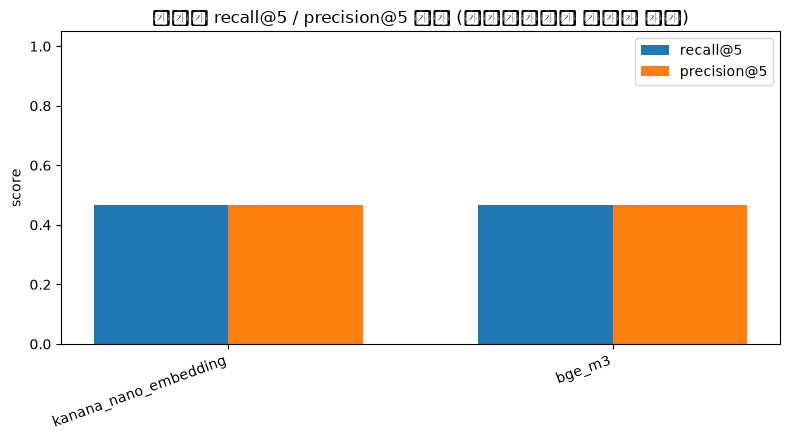

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(recommendation_results_df))
width = 0.35

ax.bar(
    [i - width / 2 for i in x],
    recommendation_results_df["recall@5"],
    width=width,
    label="recall@5",
)
ax.bar(
    [i + width / 2 for i in x],
    recommendation_results_df["precision@5"],
    width=width,
    label="precision@5",
)

ax.set_xticks(list(x))
ax.set_xticklabels(recommendation_results_df["model"], rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("score")
ax.set_title("모델별 recall@5 / precision@5 비교 (플레이스홀더 코퍼스 기준)")
ax.legend()
fig.tight_layout()
plt.show()

### 결론 (5. CLIP 이미지 임베딩 비교)

- **recall@5/precision@5 기준으로 `clip-vit-b32-multilingual`이 텍스트 후보 대비 우위인지**:
  판단 불가 — **실행 자체가 실패했다**(`[clip_vit_b32_multilingual] 추천 벤치마크 실패: Modality
  'image' is not supported by this SentenceTransformer model. Supported modalities: text.`).
  원인은 모델 성능이 아니라 **구현 버그**다: `sentence-transformers/clip-ViT-B-32-multilingual-v1`은
  원본 CLIP의 이미지 타워를 재사용하는 모델이 아니라, **텍스트 전용** 지식증류 모델이다(다국어
  텍스트를 원본 `clip-ViT-B-32`의 텍스트 임베딩 공간에 맞추도록 학습됨). sentence-transformers
  공식 사용법도 "이미지는 원본 `clip-ViT-B-32`로, 텍스트는 멀티링구얼 버전으로 각각 인코딩해서
  **같은 벡터 공간**에서 비교"하는 2-모델 조합 방식이다. 이번 구현은 이 조합을 놓치고 한 모델에
  이미지·텍스트 인코딩을 다 맡기려 해서 실패했다 — `recommendation_benchmark.py`의
  `clip_vit_b32_multilingual` 후보 정의를 고쳐야 한다(이미지 인코딩용 `load_sentence_transformer(
  "sentence-transformers/clip-ViT-B-32")` 번들을 별도로 로드해 `embed_corpus_fn`에 쓰고, 텍스트
  인코딩은 지금처럼 멀티링구얼 번들 유지).
- **지연시간/로드 시간/메모리 관점에서 우려되는 후보**: `bge_m3`의 로드 시간이 198.99초로
  `kanana_nano_embedding`(11.65초)의 약 17배, peak 메모리도 153.7MB로 kanana(1.4MB)보다 훨씬 크다.
  반대로 **추론 지연시간은 kanana가 mean 2641.8ms로 bge_m3(200.0ms)의 약 13배 느리다** — 로드는
  가볍고 추론은 무거운 kanana, 로드는 무겁고 추론은 가벼운 bge_m3로 정반대 트레이드오프다. chat_agent
  쪽 5.3(임베딩 모델 비교)에서도 kanana_nano_embedding의 추론 지연시간이 다른 후보 대비 유독 느리게
  나왔던 것과 같은 패턴이 여기서도 재현됐다.
- **현재 baseline(`kanana_nano_embedding`) 대비 채택을 고려해볼 만한 후보**: 이번 3-쿼리 표본에서는
  `kanana_nano_embedding`과 `bge_m3`의 recall@3(33.3%)/precision@3(55.6%)/recall@5·precision@5
  (46.7%)가 **완전히 동일**하게 나왔다 — 쿼리 3개·카테고리당 5개짜리 코퍼스라 recall/precision이
  가질 수 있는 값 자체가 몇 개 안 되는 이산적인 지표라서(분해능이 낮아서) 실제로는 다른 랭킹인데
  우연히 같은 집계값이 됐을 가능성이 크다 — 이 결과만으로 두 모델의 품질 차이를 판단할 근거는 없다.
  다만 위 1~3번 섹션의 정성적 랭킹(같은 5개 상품 기준)에서는 bge_m3가 "리바이스 데님 자켓"을
  1위로 올려 더 그럴듯했고, 추론 지연시간도 13배 빠르다 — 품질이 동등하다면 속도 면에서 bge_m3가
  더 유력한 후보다. CLIP은 버그로 판단 보류.
- **후속 조치**:
  1. `clip_vit_b32_multilingual` 후보의 이미지 인코딩 버그 수정(원본 `clip-ViT-B-32` 이미지 타워
     로 교체) 후 재실행 — 이번 절의 원래 목적(LAB-10의 "CLIP 이미지 임베딩" 전제 검증)을 아직
     달성하지 못했다.
  2. recall/precision 해상도가 너무 낮아 모델 간 차이를 못 가른다 — 쿼리·카테고리 수를 늘려
     재검증 필요.
  3. 실제 상품 이미지가 확보되면 플레이스홀더 코퍼스(`ashraq/fashion-product-images-small`)를
     교체해 재검증.
  4. 위 사유로 `model_registry.ACTIVE_EMBEDDING` 갱신은 이번 결과만으로는 시기상조.

---
## 6. 방향 B — 라이브 방송 추천 규칙기반 재순위화 프로토타입

LAB-14 방향 B 제안: "지금 볼 방송/다음 볼 방송을 추천"은 상품 추천과 추천 대상 자체가 다르다
(아이템 = 방송). 콜드스타트가 상품보다 심해서(방송 종료 시 후보 소멸) 별도 모델을 학습하는 대신
"배치 후보 생성(방향 A 임베딩 재사용) + 실시간 신호 규칙기반 재순위화" 2단계를 제안했다. 이 섹션은
그중 실시간 재순위화 부분을 `live_recommendation.py`(모델 없는 규칙 기반 가중합 스코어링 모듈)로
프로토타입한다 — 배치 후보 생성(방송 대표 벡터)은 방향 A가 확정된 뒤 별도로 구현한다.

가중치는 임의 초기값이다(실데이터 없음) — 아래 결과는 로직이 의도대로 동작하는지 정성적으로
확인하는 용도이지, "이 가중치가 맞다"는 결론이 아니다.

In [6]:
from live_recommendation import LiveSessionSignal, rerank_sessions

# 더미 방송 로그 — 실제 시청자/좋아요/팔로우 데이터가 없어 손으로 구성했다.
dummy_live_sessions = [
    LiveSessionSignal(
        broadcast_id="live_1", viewer_count=850, recent_like_rate=0.62, is_followed_seller=True
    ),
    LiveSessionSignal(
        broadcast_id="live_2", viewer_count=120, recent_like_rate=0.15, is_followed_seller=False
    ),
    LiveSessionSignal(
        broadcast_id="live_3", viewer_count=430, recent_like_rate=0.80, is_followed_seller=False
    ),
    LiveSessionSignal(
        broadcast_id="live_4", viewer_count=60, recent_like_rate=0.05, is_followed_seller=True
    ),
]

for signal, score in rerank_sessions(dummy_live_sessions):
    print(f"{score:.3f}  {signal.broadcast_id}  (viewer={signal.viewer_count}, "
          f"like_rate={signal.recent_like_rate}, followed={signal.is_followed_seller})")

0.788  live_1  (viewer=850, like_rate=0.62, followed=True)
0.492  live_3  (viewer=430, like_rate=0.8, followed=False)
0.244  live_4  (viewer=60, like_rate=0.05, followed=True)
0.108  live_2  (viewer=120, like_rate=0.15, followed=False)
